In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, GridSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay,
                             log_loss, cohen_kappa_score)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
R = {}
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
CLASSES = ["Low", "Moderate", "High"]          # ordinal order

In [2]:
df = pd.read_csv(r"C:\Users\harsh\Downloads\diabetes_risk.csv")
df = df.drop(columns="patient_id")

In [3]:
y = df["diabetes_risk"].map({c: i for i, c in enumerate(CLASSES)})
X = df.drop(columns="diabetes_risk")
R["shape"] = list(df.shape)
R["class_counts"] = df["diabetes_risk"].value_counts().reindex(CLASSES).to_dict()
R["missing"] = {k: int(v) for k, v in X.isna().sum().items() if v > 0}
R["duplicates"] = int(df.duplicated().sum())

In [4]:
print('Shape:', df.shape)
print('Class counts:', R['class_counts'])
print('Missing values:', R['missing'])
print('Duplicates:', R['duplicates'])
df.head()

Shape: (15000, 18)
Class counts: {'Low': 9000, 'Moderate': 3750, 'High': 2250}
Missing values: {'smoking_status': 472, 'alcohol_consumption': 3788, 'income_bracket': 463}
Duplicates: 0


,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [5]:
num_cols = ["age", "bmi", "hours_sleep_per_night", "stress_level", "fasting_blood_sugar",
            "hba1c_level", "blood_pressure_systolic", "blood_pressure_diastolic", "waist_circumference_cm"]
cat_cols = ["gender", "city", "family_history_diabetes", "physical_activity_level", "diet_type",
            "smoking_status", "alcohol_consumption", "income_bracket"]

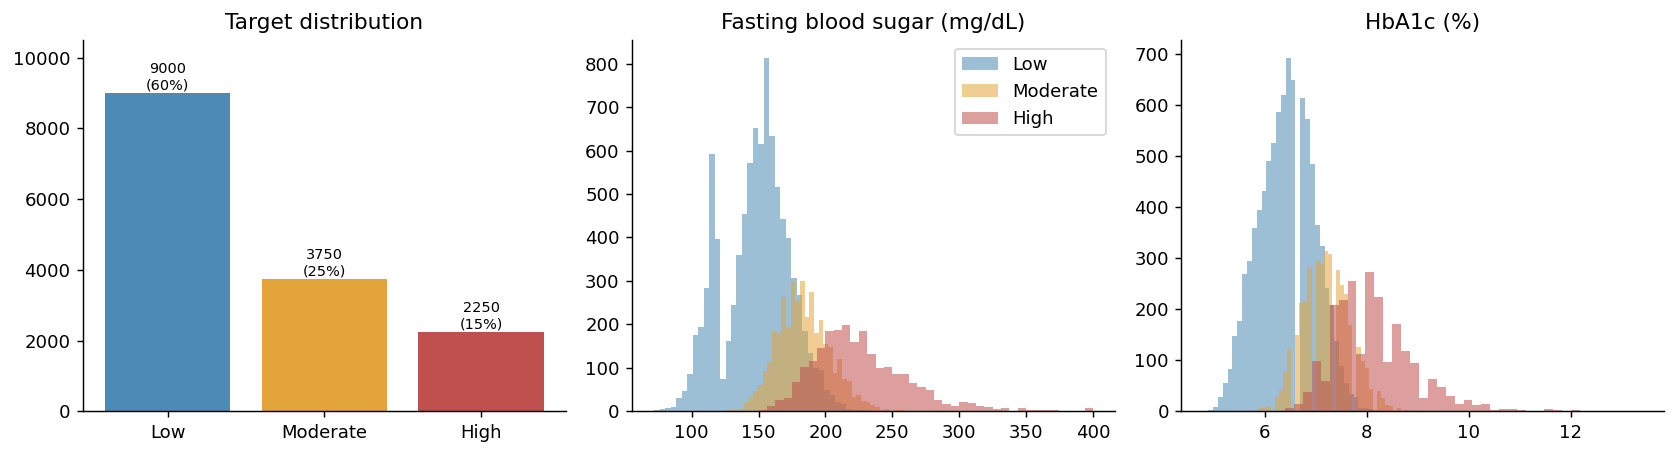

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
cnt = [R["class_counts"][c] for c in CLASSES]
ax[0].bar(CLASSES, cnt, color=["#4C8BB5", "#E3A53B", "#C0504D"])
for i, v in enumerate(cnt): ax[0].text(i, v + 100, f"{v}\n({v/len(df):.0%})", ha="center", fontsize=8)
ax[0].set_ylim(0, 10500); ax[0].set_title("Target distribution")
for c, col in zip(CLASSES, ["#4C8BB5", "#E3A53B", "#C0504D"]):
    ax[1].hist(df.loc[df.diabetes_risk == c, "fasting_blood_sugar"], bins=40, alpha=.55, color=col, label=c)
    ax[2].hist(df.loc[df.diabetes_risk == c, "hba1c_level"], bins=40, alpha=.55, color=col, label=c)
ax[1].set_title("Fasting blood sugar (mg/dL)"); ax[2].set_title("HbA1c (%)"); ax[1].legend()
plt.tight_layout(); plt.savefig("d_fig_eda1.png"); plt.show()

In [7]:
spread = {}
for c in cat_cols:
    s = pd.crosstab(X[c].fillna("Missing"), y, normalize="index")[2]
    spread[c] = float(s.max() - s.min())
R["cat_spread_high"] = dict(sorted(spread.items(), key=lambda kv: -kv[1]))
R["group_means"] = df.groupby("diabetes_risk")[num_cols].mean().loc[CLASSES].round(2).T.to_dict()

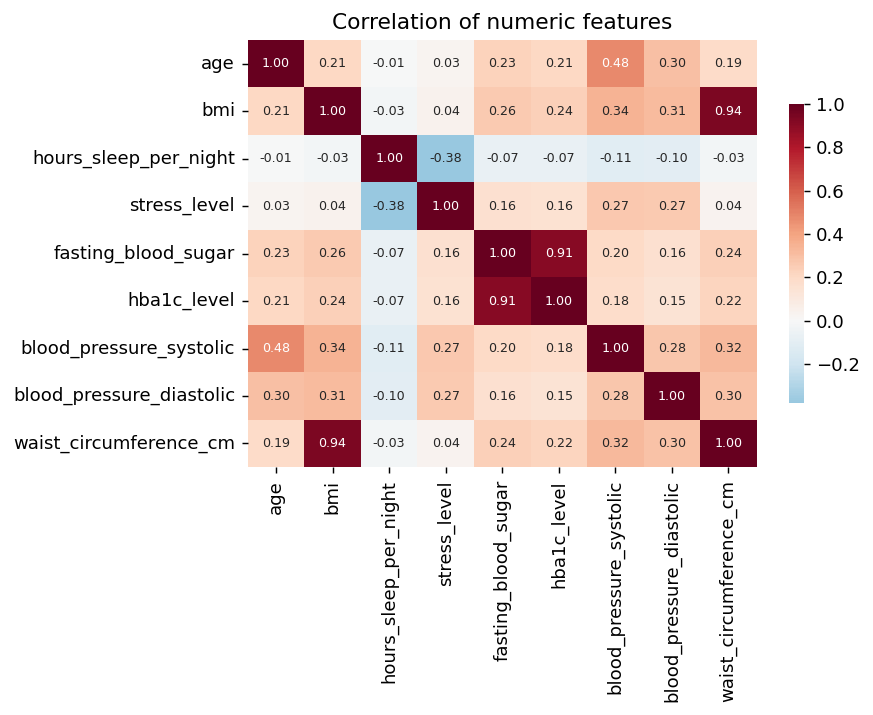

In [8]:
plt.figure(figsize=(7, 5.6))
sns.heatmap(df[num_cols].corr(), cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": .7})
plt.title("Correlation of numeric features"); plt.tight_layout(); plt.savefig("d_fig_corr.png"); plt.show()
R["bmi_waist_corr"] = float(df.bmi.corr(df.waist_circumference_cm))

In [9]:
from scipy.stats import chi2_contingency
R["missing_chi2_p"] = {c: float(chi2_contingency(pd.crosstab(X[c].isna(), y))[1])
                       for c in ["smoking_status", "alcohol_consumption", "income_bracket"]}
R["clinical_ranges"] = {"fbs>=126": float((df.fasting_blood_sugar >= 126).mean()),
                        "hba1c>=6.5": float((df.hba1c_level >= 6.5).mean())}

In [10]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
R["split"] = {"train": len(X_tr), "test": len(X_te)}

In [11]:
class DiabetesFeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        # --- glycaemic features
        X["eag_from_hba1c"] = 28.7 * X["hba1c_level"] - 46.7           
        X["fbs_hba1c_product"] = X["fasting_blood_sugar"] * X["hba1c_level"]
        X["fbs_ge_126"] = (X["fasting_blood_sugar"] >= 126).astype(int)      
        X["hba1c_ge_6_5"] = (X["hba1c_level"] >= 6.5).astype(int)
        X["both_glycaemic_flags"] = X["fbs_ge_126"] * X["hba1c_ge_6_5"]


        
        # --- blood pressure
        X["pulse_pressure"] = X["blood_pressure_systolic"] - X["blood_pressure_diastolic"]
        X["mean_arterial_pressure"] = X["blood_pressure_diastolic"] + X["pulse_pressure"] / 3
        X["hypertension_flag"] = ((X["blood_pressure_systolic"] >= 140) |
                                  (X["blood_pressure_diastolic"] >= 90)).astype(int)
        # --- adiposity (BMI and waist are 0.94 correlated, so use the ratio / residual-style term)
        X["waist_per_bmi"] = X["waist_circumference_cm"] / X["bmi"]
        X["bmi_overweight_asian"] = (X["bmi"] >= 23).astype(int)               # WHO Asian cut-offs
        X["bmi_obese_asian"] = (X["bmi"] >= 27.5).astype(int)
        # --- age and lifestyle
        X["age_x_bmi"] = X["age"] * X["bmi"]
        X["age_ge_45"] = (X["age"] >= 45).astype(int)
        act = X["physical_activity_level"].map({"Active": 0, "Moderate": 1, "Sedentary": 2})
        fam = (X["family_history_diabetes"] == "Yes").astype(int)
        X["lifestyle_risk_score"] = act + fam + X["bmi_overweight_asian"]
        X["sleep_deviation"] = (X["hours_sleep_per_night"] - 7.5).abs()
        return X

In [12]:
ordinal_maps = {"physical_activity_level": ["Active", "Moderate", "Sedentary"],
                "income_bracket": ["Low", "Middle", "High"],
                "smoking_status": ["Never", "Former", "Current"],
                "alcohol_consumption": ["Never", "Occasional", "Regular"]}


def build_preprocessor(engineered):
    num = list(num_cols)
    if engineered:
        num += ["eag_from_hba1c", "fbs_minus_eag", "fbs_hba1c_product", "pulse_pressure",
                "mean_arterial_pressure", "waist_per_bmi", "age_x_bmi", "lifestyle_risk_score", "sleep_deviation"]
    flags = ["fbs_ge_126", "hba1c_ge_6_5", "both_glycaemic_flags", "hypertension_flag",
             "bmi_overweight_asian", "bmi_obese_asian", "age_ge_45"] if engineered else []
    ord_cols = list(ordinal_maps)
    nominal = ["gender", "diet_type", "family_history_diabetes", "city"]
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("flags", "passthrough", flags),
        ("ord", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("enc", OrdinalEncoder(categories=[ordinal_maps[c] + ["Missing"] for c in ord_cols]))]),
         ord_cols),
        ("nom", OneHotEncoder(handle_unknown="ignore", min_frequency=30), nominal),
    ])


def make_pipe(clf, engineered=True):
    steps = ([("fe", DiabetesFeatureEngineer())] if engineered else [])
    steps += [("prep", build_preprocessor(engineered)), ("clf", clf)]
    return Pipeline(steps)

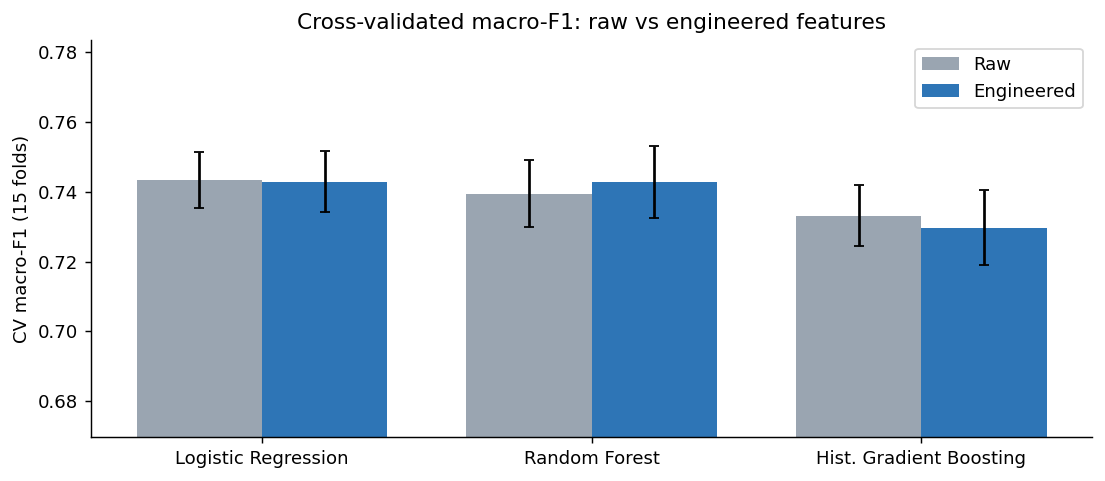

In [13]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
scoring = {"accuracy": "accuracy", "bal_acc": "balanced_accuracy", "macro_f1": "f1_macro",
           "roc_auc": "roc_auc_ovr", "neg_logloss": "neg_log_loss"}
candidates = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=3000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    "Hist. Gradient Boosting": HistGradientBoostingClassifier(random_state=SEED),
}
rows = []
for name, clf in candidates.items():
    for eng in ([False] if name.startswith("Dummy") else [False, True]):
        res = cross_validate(make_pipe(clf, eng), X_tr, y_tr, cv=cv, scoring=scoring, n_jobs=-1)
        r = {"Model": name, "Features": "Engineered" if eng else "Raw"}
        for m in scoring:
            r[m] = float(res[f"test_{m}"].mean() * (-1 if m == "neg_logloss" else 1))
            r[m + "_sd"] = float(res[f"test_{m}"].std())
        rows.append(r)
cmp_df = pd.DataFrame(rows); cmp_df.to_csv("d_cv_comparison.csv", index=False)
R["cv_table"] = cmp_df.round(4).to_dict(orient="records")

fig, ax = plt.subplots(figsize=(8.6, 3.8))
pdf = cmp_df[~cmp_df.Model.str.startswith("Dummy")]
models = list(pdf.Model.unique()); w = .38; xs = np.arange(len(models))
for k, (feat, col) in enumerate([("Raw", "#9AA5B1"), ("Engineered", "#2E75B6")]):
    sub = pdf[pdf.Features == feat].set_index("Model").loc[models]
    ax.bar(xs + (k - .5) * w, sub["macro_f1"], w, yerr=sub["macro_f1_sd"], label=feat, color=col, capsize=3)
ax.set_xticks(xs); ax.set_xticklabels(models); ax.set_ylabel("CV macro-F1 (15 folds)")
ax.set_title("Cross-validated macro-F1: raw vs engineered features"); ax.legend()
lo = max(0, pdf.macro_f1.min() - .06); ax.set_ylim(lo, pdf.macro_f1.max() + .04)
plt.tight_layout(); plt.savefig("d_fig_cv.png"); plt.show()

In [14]:
cmp_df[['Model','Features','accuracy','bal_acc','macro_f1','macro_f1_sd','roc_auc','neg_logloss']].round(4)

,Model,Features,accuracy,bal_acc,macro_f1,macro_f1_sd,roc_auc,neg_logloss
0,Dummy (most frequent),Raw,0.6000,0.3333,0.2500,0.0000,0.5000,14.4175
1,Logistic Regression,Raw,0.7932,0.7317,0.7435,0.0080,0.9180,0.4599
2,Logistic Regression,Engineered,0.7928,0.7311,0.7429,0.0087,0.9178,0.4603
3,Random Forest,Raw,0.7913,0.7252,0.7394,0.0096,0.9132,0.4879
4,Random Forest,Engineered,0.7916,0.7287,0.7427,0.0103,0.9138,0.4737
5,Hist. Gradient Boosting,Raw,0.7837,0.7223,0.7332,0.0087,0.9093,0.5012
6,Hist. Gradient Boosting,Engineered,0.7817,0.7182,0.7297,0.0108,0.9086,0.5052


In [ ]:
grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10]},
    "Hist. Gradient Boosting": {"clf__learning_rate": [0.05], "clf__max_depth": [3, 5],
                                "clf__l2_regularization": [1.0, 10.0], "clf__max_iter": [100]},
}
inner = StratifiedKFold(5, shuffle=True, random_state=1)
outer = StratifiedKFold(5, shuffle=True, random_state=2)
nested, tuned = {}, {}
for name, grid in grids.items():
    gs = GridSearchCV(make_pipe(candidates[name], True), grid, cv=inner, scoring="f1_macro", n_jobs=-1)
    sc = cross_validate(gs, X_tr, y_tr, cv=outer, scoring={"macro_f1": "f1_macro", "accuracy": "accuracy",
                                                             "roc_auc": "roc_auc_ovr"}, n_jobs=1)
    gs.fit(X_tr, y_tr); tuned[name] = gs
    nested[name] = {k: [float(sc[f"test_{k}"].mean()), float(sc[f"test_{k}"].std())]
                    for k in ["macro_f1", "accuracy", "roc_auc"]}
    nested[name]["best_params"] = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
R["nested"] = nested
final_name = max(nested, key=lambda n: nested[n]["macro_f1"][0])
R["final_model"] = final_name
final = tuned[final_name].best_estimator_

In [ ]:
for k, v in nested.items():
    print(k, '| macro-F1 %.3f +/- %.3f | acc %.3f | AUC %.3f' % (v['macro_f1'][0], v['macro_f1'][1], v['accuracy'][0], v['roc_auc'][0]), v['best_params'])
print('Final model:', final_name)

In [ ]:
proba = final.predict_proba(X_te)
pred = proba.argmax(1)
cm = confusion_matrix(y_te, pred)
R["test"] = {"accuracy": accuracy_score(y_te, pred), "balanced_accuracy": balanced_accuracy_score(y_te, pred),
             "macro_f1": f1_score(y_te, pred, average="macro"),
             "weighted_f1": f1_score(y_te, pred, average="weighted"),
             "roc_auc_ovr": roc_auc_score(y_te, proba, multi_class="ovr"),
             "log_loss": log_loss(y_te, proba), "kappa": cohen_kappa_score(y_te, pred),
             "qw_kappa": cohen_kappa_score(y_te, pred, weights="quadratic")}
R["test_per_class_auc"] = {c: float(roc_auc_score((y_te == i).astype(int), proba[:, i])) for i, c in enumerate(CLASSES)}
R["confusion"] = cm.tolist()
R["report"] = classification_report(y_te, pred, target_names=CLASSES, digits=3, output_dict=True)
R["report_text"] = classification_report(y_te, pred, target_names=CLASSES, digits=3)
R["adjacent_error_share"] = float(((np.abs(pred - y_te.values) == 1).sum()) / max(1, (pred != y_te.values).sum()))
R["test_baseline_acc"] = float((y_te == 0).mean())
rng = np.random.RandomState(SEED); yt = y_te.values; b = {"accuracy": [], "macro_f1": []}
for _ in range(2000):
    i = rng.randint(0, len(yt), len(yt))
    b["accuracy"].append(accuracy_score(yt[i], pred[i])); b["macro_f1"].append(f1_score(yt[i], pred[i], average="macro"))
R["test_ci"] = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in b.items()}

raw_ref = make_pipe(candidates[final_name], False); raw_ref.fit(X_tr, y_tr)
R["test_raw_same_model"] = {"accuracy": accuracy_score(y_te, raw_ref.predict(X_te)),
                            "macro_f1": f1_score(y_te, raw_ref.predict(X_te), average="macro")}

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=CLASSES, cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=CLASSES, cmap="Blues", ax=ax[1],
                                        colorbar=False, normalize="true", values_format=".2f")
ax[1].set_title("Confusion matrix (row-normalised = recall)")
plt.tight_layout(); plt.savefig("d_fig_cm.png"); plt.show()

In [ ]:
print(pd.Series(R['test']).round(4).to_string())
print('\n95% bootstrap CI:', {k: [round(x,3) for x in v] for k, v in R['test_ci'].items()})
print('Per-class AUC:', {k: round(v,3) for k, v in R['test_per_class_auc'].items()})
print('Share of errors that are one class away: %.1f%%' % (100*R['adjacent_error_share']))
print('\n', R['report_text'])

In [ ]:
sizes, trs, vas = learning_curve(final, X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=4),
                                 scoring="f1_macro", train_sizes=np.linspace(.15, 1, 6), n_jobs=-1)
plt.figure(figsize=(6.2, 3.8))
for arr, lab, col in [(trs, "Training", "#2E75B6"), (vas, "Validation", "#C0504D")]:
    plt.plot(sizes, arr.mean(1), "o-", label=lab, color=col)
    plt.fill_between(sizes, arr.mean(1) - arr.std(1), arr.mean(1) + arr.std(1), alpha=.15, color=col)
plt.xlabel("Training samples"); plt.ylabel("Macro-F1"); plt.title("Learning curve (final model)")
plt.legend(); plt.tight_layout(); plt.savefig("d_fig_learning.png"); plt.show()
R["learning"] = {"train_end": float(trs.mean(1)[-1]), "val_end": float(vas.mean(1)[-1])}

pi = permutation_importance(final, X_te, y_te, scoring="f1_macro", n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_te.columns); sd = pd.Series(pi.importances_std, index=X_te.columns)
imp = imp.sort_values(ascending=False)
R["perm_importance"] = imp.round(4).to_dict()
top = imp.head(10)[::-1]
plt.figure(figsize=(7, 4)); plt.barh(top.index, top.values, xerr=sd[top.index].values, color="#2E75B6")
plt.xlabel("Mean drop in test macro-F1 when shuffled"); plt.title("Permutation importance (original inputs)")
plt.tight_layout(); plt.savefig("d_fig_imp.png"); plt.show()

# calibration of P(High)
from sklearn.calibration import calibration_curve
fp_, mp_ = calibration_curve((y_te == 2).astype(int), proba[:, 2], n_bins=6, strategy="quantile")
R["calibration_high"] = {"observed": fp_.round(3).tolist(), "predicted": mp_.round(3).tolist()}

# errors by the two key glycaemic markers
err = X_te.assign(true=y_te.values, pred=pred, wrong=(pred != y_te.values))
R["err_rate_by_hba1c_band"] = err.groupby(pd.cut(err.hba1c_level, [0, 6.0, 6.5, 7.0, 7.5, 8.0, 20]),
                                          observed=True)["wrong"].mean().round(3).rename(str).to_dict()

In [ ]:
print('Learning curve end-points:', R['learning'])
print('Calibration of P(High):', R['calibration_high'])
print('Error rate by HbA1c band:', R['err_rate_by_hba1c_band'])
print('\nPermutation importance:')
print(pd.Series(R['perm_importance']).round(4).to_string())